# 05 · Case study: the 2026 Cleveland Browns, plus the clutch gene

Phases 0-3 found that the 1st-half late "surge" is a **valuation effect** (EPA prices late plays higher; raw outcomes are flat), and that the 2nd-half late dip comes from **leaders going conservative**. This notebook takes those lessons to the 2026 Browns, who are 6-4 with every win coming on a 4th-quarter go-ahead drive, and then asks whether "clutch" exists at all.

Question doc: `question-doc.md` **v1.7** (§7). Pre-spec below was written before any 2026 output was seen.

## Pre-spec (§7, doc v1.7, written 2026-11-20, before any output)

**Data.** nflverse pbp 2016-2026, regular season. 2026 cut-off: **through Week 10** (`CUTOFF_WEEK`; Week 11 is CLE's bye). Plays = the notebook-01 filter (no kneels, spikes, 2-pt, rows without a down). Checked by reproducing Claim A (+0.079). OT is left out of every by-quarter number.

**Metrics, clock-neutral first.** `succ_raw` (yardage success: 40% of distance on 1st down, 60% on 2nd, 100% on 3rd/4th, no turnover), `fd` (first-down rate: gained the distance, no turnover), `yds` (yards/play), drive scoring rate (TD or FG), points per drive (TD = 7, FG = 3). **EPA is shown alongside, never alone** (§6 lesson: its baseline moves with the clock).

**Game flags** (built from the pbp score timeline):
- **4th-quarter comeback win (`cb`)**: won, and trailed at some point in the 4th quarter (entering it or after any 4th-quarter play). Stricter `cb_strict`: also trailed by 1-8 at some point in the 4th (PFR/Kacsmar style). Ties don't count as wins.
- **Game-winning drive (`gwd`)**: won, and took the lead for good in the 4th quarter or OT. This counts any go-ahead score, including the rare defensive or special-teams one (Kacsmar requires an offensive drive).
- **Sanity gate:** the definitions must give CLE 2026 a 6-4 record and **6 GWD wins** before anything uses them on history. If they don't, fix the definition first and log it.

**Q1. Good 4th quarter, or bad quarters 1-3?** CLE 2026 by quarter vs the 2026 league (other teams) and vs CLE 2025. Tests: CLE minus league in Q1-3 and in Q4, plus the difference between the two, with intervals from resampling games. *Reading:* Q1-3 below the league and Q4 ≈ league means "slow starters, average finishers". Q4 above the league with an interval clear of 0 means a genuine late edge, which goes to Q2.

**Q2. Better than a normal team in the same spot?** CLE plays and drives in the 4th quarter when **trailing or tied**, vs league teams in the same cells (margin bins tied / 1-3 / 4-8 / 9-16 / 17+ down × time bins 15:00-10:00 / 10:00-5:00 / 5:00-2:00 / 2:00-0:00 of the 4th). The matched gap asks what the league would do with CLE's exact mix of situations. *Reading:* a matched gap ≈ 0 means game state explains it; a gap clear of 0 means CLE really was better than typical comeback teams.

**Q3. How much is the opponent?** Opponents' offense when **leading CLE** in the 4th quarter vs league leaders in the same cells (lead bins 1-3 / 4-8 / 9-16 / 17+ × the same time bins). Measures: run rate, clock seconds per play, success, first-down rate, yds/play, EPA; drive score rate, three-and-out rate, points per drive. The defensive side of this question is Q2 by construction (CLE offense vs league trailing offenses in the same cells = opponents' defense vs league leading defenses), so it isn't repeated. *Reading:* opponents below matched leaders means part of the comeback is the opponent stalling. Points attribution: CLE excess points (Q2 gap × CLE drives) vs points the opponents left on the table (Q3 gap × their drives).

**Q4. Will it last? (team level, 2016-2025)** Split each team-season into games 1-10 ("early", matching CLE's 10 games) and 11+ ("rest"). **Unusual = 4 or more GWD wins in the first 10 games** (sensitivity: top 5% of the distribution). For flagged team-seasons: early vs rest win %, GWD and comeback rate per game, one-score win %, plus next-season win %. Also across all team-seasons: does early one-score win % predict rest one-score win % (min 3 early and 2 rest one-score games)? Compared with early point differential per game. *Reading:* a big drop from early to rest, and one-score record not predicting, means comeback runs are mostly luck that regresses. CLE 2026 gets a rest-of-season forecast from point differential + one-score record fitted on history.

**Q5. Clutch gene (persistence test).** Clutch window = **4th quarter, last 5:00 (`gsr` ≤ 300), offense trailing or tied by 0-8** (needs to score). Sensitivity: |margin| ≤ 8 (adds one-score leads). Unit = QB (dropbacks, QB id = passer id, or rusher id on scrambles; ids, not names), and team (all plays). Residual per unit-season = clutch mean − non-clutch mean − that season's league clutch-minus-normal gap. Metrics: `succ_raw` (primary), `fd`, `yds`; EPA as a secondary check.
- Persistence: (a) **split-half**: odd vs even team games in the same season, min 12 clutch and 100 other plays in each half; (b) **season t vs t+1**: min 25 clutch and 200 other plays in each season.
- **Noise baseline:** reshuffle which plays count as clutch within each unit-season (same counts), 100 times. This gives the band of correlations noise alone produces. **Detectability reference:** on the same reshuffles, the persistence of the unit's raw *level* on clutch-sized samples. This shows how much real, stable skill shows through on samples this small.
- *Reading:* r above the noise band means clutch is real-ish, and the next-season forecast for a clutch residual = r × this season's residual. r inside the band means it's mostly luck (judged against the detectability reference: if even true skill barely shows on samples this small, the test is weak, and that's said too). Watson 2026 and CLE 2026 are then placed on the distribution.

**Sample-size warning.** 10 games is tiny. Q1-Q3 are descriptive, with intervals that resample CLE's games (and the league's). Q4-Q5 are where the real inference is (hundreds of team-seasons and QB-seasons). Intervals: `NBOOT` = 1000 game (or unit) resamples, percentile 95%.

**Change log (after seeing data, 2026-11-20).** No definition, threshold or test was changed after outputs were seen. These are the notes from the run:
- *Filter:* this notebook keeps 119-311 more plays per season than `plays.parquet` (0.4-0.9%), but Claim A reproduces exactly (+0.079 [+0.065, +0.092]), so `FILTER = "type"` stays.
- *Score timeline:* 48 team-games (24 games, 0.9% of 2,789) have a timeline final margin that doesn't match the official final, and 3 comeback wins aren't flagged as GWD wins. Both come from nflverse score columns in a handful of games. CLE 2026 passes the gate (6-4, 6 GWD wins), so they're left in. They can move Q4 history by under 1% of games.
- *CLE comeback count:* 4 comeback wins (weeks 2, 3, 6, 10). Weeks 4 (PIT) and 7 (TEN) were go-ahead drives from a tie, so "six comebacks" is wrong; "six game-winning drives" is right.
- *Q4 sensitivity:* the top-5% threshold came out at 4, the same as `GWD_MIN`, so the sensitivity rows duplicate the primary ones. Left as pre-specified.

## Setup and data
`REFRESH = True` re-downloads the pbp (needed when the cached 2026 data is older than the cut-off week). The cache keeps only the columns used here.

In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

DATA, RES = Path("../data"), Path("../results")
RES.mkdir(exist_ok=True)
SEASONS = list(range(2016, 2027)); CUR = 2026; CUTOFF_WEEK = 10; TEAM = "CLE"
NBOOT, NSHUF, SEED = 1000, 100, 5           # NBOOT 300 / NSHUF 30 while iterating
REFRESH = False
FILTER = "type"                              # "type" (pass/run play_type) or "flags" (pass|rush flags); see Checks
EARLY_N, GWD_MIN = 10, 4
CLUTCH_GSR, CLUTCH_MARGIN = 300, 8
MIN_HALF, MIN_O_HALF, MIN_SEASON, MIN_O_SEASON = 12, 100, 25, 200

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a9a"
plt.rcParams.update({"axes.grid": True, "grid.alpha": .3, "lines.linewidth": 1.2,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
rng = np.random.default_rng(SEED)

In [22]:
KEEP = ["game_id", "play_id", "season", "week", "season_type", "home_team", "away_team", "posteam", "defteam",
        "qtr", "down", "ydstogo", "yardline_100", "game_seconds_remaining", "half_seconds_remaining",
        "play_type", "yards_gained", "epa", "pass", "rush", "qb_dropback", "qb_kneel", "qb_spike",
        "two_point_attempt", "sack", "interception", "fumble_lost", "touchdown", "score_differential",
        "total_home_score", "total_away_score", "home_score", "away_score", "fixed_drive", "fixed_drive_result",
        "passer_player_id", "passer_player_name", "rusher_player_id", "rusher_player_name", "no_huddle"]
cache = DATA / "pbp05_2016_2026.parquet"
if cache.exists() and not REFRESH:
    raw = pd.read_parquet(cache)
else:
    import nflreadpy as nfl
    parts = []
    for s in SEASONS:                                            # one season at a time keeps memory down
        pl = nfl.load_pbp([s])
        miss = [c for c in KEEP if c not in pl.columns]
        if miss: print(s, "missing columns:", miss)
        parts.append(pl.select([c for c in KEEP if c in pl.columns]).to_pandas())
    raw = pd.concat(parts, ignore_index=True)
    raw.to_parquet(cache)

print("latest 2026 week in the data:", raw.loc[raw.season == CUR, "week"].max(), "| cut-off:", CUTOFF_WEEK)
raw = raw[(raw.season_type == "REG") & ((raw.season < CUR) | (raw.week <= CUTOFF_WEEK))].copy()
for c in ["posteam", "defteam", "home_team", "away_team"]:         # relocations -> one id per franchise
    raw[c] = raw[c].replace({"OAK": "LV", "SD": "LAC", "STL": "LA"})
raw = raw.sort_values(["game_id", "play_id"]).reset_index(drop=True)
print(raw.groupby("season").game_id.nunique().rename("games").to_frame().T.to_string())

latest 2026 week in the data: 10 | cut-off: 10
season  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
games    256   256   256   256   256   272   271   272   272   272   150


### Prep: plays `P`, drives `D`, team-games `GR`
New pandas moves: `np.select` picks a value per row from several conditions (the success threshold by down). `groupby(...).shift(-1)` looks at the next play in the same drive (clock seconds used per play). The score timeline loop walks each game's plays once to find the 4th-quarter deficit and the moment the winner took the lead for good.

In [23]:
r = raw
z = lambda s: s.fillna(0)
base = z(r.qb_kneel).eq(0) & z(r.qb_spike).eq(0) & z(r.two_point_attempt).eq(0) & r.down.notna() & r.posteam.notna()
keep = r.play_type.isin(["pass", "run"]) if FILTER == "type" else ((z(r["pass"]).eq(1) | z(r.rush).eq(1)) & r.epa.notna())
P = r[base & keep].copy()
P["half"] = np.where(P.qtr <= 2, 1, np.where(P.qtr <= 4, 2, 3))
P["gsr"], P["hsr"], P["sd"] = P.game_seconds_remaining, P.half_seconds_remaining, P.score_differential
P["yds"] = z(P.yards_gained)
P["turnover"] = (z(P.interception) + z(P.fumble_lost)).clip(upper=1)
P["fd"] = ((P.yds >= P.ydstogo) & P.turnover.eq(0)).astype(float)
need = np.select([P.down.eq(1), P.down.eq(2)], [0.4 * P.ydstogo, 0.6 * P.ydstogo], P.ydstogo)
P["succ_raw"] = ((P.yds >= need) & P.turnover.eq(0)).astype(float)
P["is_pass"] = z(P["pass"]).astype(float)
P["is_run"] = 1 - P.is_pass
P["secs"] = P.gsr - P.groupby(["game_id", "fixed_drive"]).gsr.shift(-1)     # clock used before the next snap
db = z(P.qb_dropback).eq(1)
P["qb_id"] = P.passer_player_id.fillna(P.rusher_player_id).where(db)
P["qb_name"] = P.passer_player_name.fillna(P.rusher_player_name).where(db)

# drives (from all rows, so kickoffs/penalties/XPs don't split anything)
R = r[r.posteam.notna() & r.fixed_drive.notna()]
D = (R.groupby(["game_id", "fixed_drive"])
      .agg(season=("season", "first"), week=("week", "first"), posteam=("posteam", "first"), defteam=("defteam", "first"),
           qtr=("qtr", "first"), qtr_end=("qtr", "last"), gsr=("game_seconds_remaining", "first"),
           gsr_end=("game_seconds_remaining", "last"), sd=("score_differential", "first"),
           result=("fixed_drive_result", "first")).reset_index())
cnt = P.groupby(["game_id", "fixed_drive"]).agg(n_plays=("fd", "size"), n_fd=("fd", "sum"))
D = D.join(cnt, on=["game_id", "fixed_drive"]).fillna({"n_plays": 0, "n_fd": 0})
D = D[D.n_plays > 0].copy()
D["pts"] = D.result.map({"Touchdown": 7, "Field goal": 3}).fillna(0)
D["score"] = (D.pts > 0).astype(float)
D["three_out"] = ((D.n_fd == 0) & D.result.eq("Punt")).astype(float)
D["dur"] = D.gsr - D.gsr_end

# score timeline -> per team-game flags
tl = r[["game_id", "qtr", "total_home_score", "total_away_score"]].copy()
tl[["total_home_score", "total_away_score"]] = tl.groupby("game_id")[["total_home_score", "total_away_score"]].ffill().fillna(0)
tl["mh"] = tl.total_home_score - tl.total_away_score
info = r.groupby("game_id")[["season", "week", "home_team", "away_team", "home_score", "away_score"]].first()
rows = []
for gid, g in tl.groupby("game_id", sort=False):
    st = np.concatenate([[0.0], g.mh.to_numpy()])               # margin (home view): start, then after each play
    q = np.concatenate([[1], g.qtr.to_numpy()])
    q4 = np.zeros(len(st), bool); i4 = np.flatnonzero(q == 4)
    if len(i4): q4[i4] = True; q4[i4[0] - 1] = True              # include the state entering Q4
    s4 = st[q4] if q4.any() else np.array([0.0])
    fin = st[-1]
    ga_q = np.nan
    if fin != 0:
        m = st * np.sign(fin)
        ga_q = q[np.flatnonzero(m <= 0).max() + 1]              # quarter of the go-ahead-for-good play
    for side, sgn in (("home", 1), ("away", -1)):
        t4 = s4 * sgn
        rows.append(dict(game_id=gid, side=side, final=fin * sgn, q4_min=t4.min(),
                         q4_one_score=bool(((t4 < 0) & (t4 >= -8)).any()), ga_q=ga_q))
GR = pd.DataFrame(rows).join(info, on="game_id")
GR["team"] = np.where(GR.side == "home", GR.home_team, GR.away_team)
GR["opp"] = np.where(GR.side == "home", GR.away_team, GR.home_team)
GR["pf"] = np.where(GR.side == "home", GR.home_score, GR.away_score)
GR["pa"] = np.where(GR.side == "home", GR.away_score, GR.home_score)
print("timeline final != official final:", int((GR.final != GR.pf - GR.pa).sum()), "team-games")
GR["margin"] = GR.pf - GR.pa
GR["win"], GR["tie"] = (GR.margin > 0).astype(float), (GR.margin == 0).astype(float)
GR["wpts"] = GR.win + 0.5 * GR.tie
GR["one_score"] = (GR.margin.abs() <= 8).astype(float)
GR["os_win"] = GR.one_score * GR.wpts
GR["trailed_q4"] = GR.q4_min < 0
GR["cb"] = (GR.win.eq(1) & GR.trailed_q4).astype(float)
GR["cb_strict"] = (GR.win.eq(1) & GR.q4_one_score).astype(float)
GR["gwd"] = (GR.win.eq(1) & (GR.ga_q >= 4)).astype(float)
GR = GR.sort_values(["team", "season", "week"])
GR["game_no"] = GR.groupby(["team", "season"]).cumcount() + 1
P = P.merge(GR[["game_id", "team", "game_no"]].rename(columns={"team": "posteam"}), on=["game_id", "posteam"], how="left")
P["par"] = P.game_no % 2
print("comeback wins that aren't GWD wins (must be 0):", int((GR.cb.eq(1) & GR.gwd.eq(0)).sum()))
print(f"share of wins that are GWD wins, 2016-2025: {GR[(GR.season < CUR) & GR.win.eq(1)].gwd.mean():.1%}")
print(f"P {len(P):,} plays | D {len(D):,} drives | GR {len(GR):,} team-games")

timeline final != official final: 48 team-games
comeback wins that aren't GWD wins (must be 0): 3
share of wins that are GWD wins, 2016-2025: 32.8%
P 346,508 plays | D 59,450 drives | GR 5,578 team-games


### Checks (gate: nothing below is read until these pass)
1. **Filter.** Rows per season vs `plays.parquet` (rows with a down), and **Claim A**: 1st-half EPA/play, last 4:00 minus rest, 2016-2025. It should be **+0.079 [0.066, 0.094]**. If it's off by more than ~0.005, flip `FILTER` to `"flags"` and rerun. If neither matches, tell me.
2. **Browns 2026 record and flags.** It must show 6-4 and 6 GWD wins. Also check the `cb` count against what you know of each game.

In [24]:
def boot_pop(games, B=None):
    games = pd.Index(pd.unique(games)); n, B = len(games), B or NBOOT
    idx = rng.integers(0, n, (B, n))
    W = np.zeros((B, n)); np.add.at(W, (np.repeat(np.arange(B), n), idx.ravel()), 1)
    return {"games": games, "W": W}

def SN(d, pop, col, cell=None, C=1):
    d = d[d[col].notna()]
    rr = pop["games"].get_indexer(d.game_id)
    if (rr < 0).any(): raise ValueError("game not in population")
    cc = d[cell].to_numpy(int) if cell else np.zeros(len(d), int)
    S, N = np.zeros((len(pop["games"]), C)), np.zeros((len(pop["games"]), C))
    np.add.at(S, (rr, cc), d[col].to_numpy(float)); np.add.at(N, (rr, cc), 1)
    return S, N

def mean_(d, pop, col):
    S, N = SN(d, pop, col)
    return S.sum() / N.sum(), (pop["W"] @ S[:, 0]) / (pop["W"] @ N[:, 0])

def gap(d, pop, col, flag):
    "mean(flag) - mean(not flag); same game draws for both sides"
    e1, d1 = mean_(d[d[flag]], pop, col); e0, d0 = mean_(d[~d[flag]], pop, col)
    return e1 - e0, d1 - d0

def matched(dt, pt, dbase, pb, col, cell=None, C=1):
    "target mean minus what the base would do with the target's mix of cells"
    St, Nt = SN(dt, pt, col, cell, C); Sb, Nb = SN(dbase, pb, col, cell, C)
    def g(st, nt, sb, nb):
        ok = nb > 0
        lb = np.divide(sb, nb, out=np.zeros_like(sb), where=ok)
        return np.where(ok, st - nt * lb, 0).sum(-1) / np.where(ok, nt, 0).sum(-1)
    return g(St.sum(0), Nt.sum(0), Sb.sum(0), Nb.sum(0)), g(pt["W"] @ St, pt["W"] @ Nt, pb["W"] @ Sb, pb["W"] @ Nb)

def ci(draws):
    return np.nanpercentile(draws, [2.5, 97.5])

def fmt(est, draws=None, k=3):
    if draws is None: return f"{est:+.{k}f}"
    lo, hi = ci(draws); return f"{est:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"

SB = []
def log(q, what, est, draws=None, note=""):
    lo, hi = ci(draws) if draws is not None else (np.nan, np.nan)
    SB.append(dict(q=q, what=what, est=est, lo=lo, hi=hi, note=note))

In [25]:
pp = DATA / "plays.parquet"
if pp.exists():
    try:
        old = pd.read_parquet(pp, columns=["season", "down"])
        cmp = pd.DataFrame({"plays.parquet": old[old.down.notna()].season.value_counts(),
                            "this notebook": P[P.season < CUR].season.value_counts()}).sort_index()
        cmp["diff"] = cmp["this notebook"] - cmp["plays.parquet"]
        print(cmp.T.to_string())
    except Exception as e:
        print("plays.parquet compare skipped:", e)

h1 = P[(P.season < CUR) & (P.half == 1)].assign(late=lambda d: d.hsr <= 240)
popH = boot_pop(h1.game_id)
e, dr = gap(h1, popH, "epa", "late")
print("Claim A check, 1st-half EPA/play late - rest:", fmt(e, dr), " (target +0.079 [0.066, 0.094])")

season          2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
plays.parquet  32039  31806  31479  31927  32296  33674  33356  33678  33161  32623
this notebook  32289  31984  31751  32046  32444  33985  33649  33836  33335  32813
diff             250    178    272    119    148    311    293    158    174    190
Claim A check, 1st-half EPA/play late - rest: +0.079 [+0.065, +0.092]  (target +0.079 [0.066, 0.094])


In [26]:
cle = GR[(GR.team == TEAM) & (GR.season == CUR)].sort_values("week")
show = cle[["week", "opp", "pf", "pa", "q4_min", "ga_q", "cb", "cb_strict", "gwd"]].rename(
    columns={"q4_min": "worst Q4 margin", "ga_q": "go-ahead qtr"})
print(show.to_string(index=False))
print(f"\nRecord {int(cle.win.sum())}-{int((cle.win + cle.tie).rsub(1).sum())}"
      f"{'-' + str(int(cle.tie.sum())) if cle.tie.sum() else ''} | GWD wins {int(cle.gwd.sum())}"
      f" | comeback wins {int(cle.cb.sum())} (strict {int(cle.cb_strict.sum())}) | games {len(cle)}")

 week opp  pf  pa  worst Q4 margin  go-ahead qtr  cb  cb_strict  gwd
    1 JAX  10  34            -31.0           1.0 0.0        0.0  0.0
    2  TB  23  19             -3.0           4.0 1.0        1.0  1.0
    3 CAR  21  18             -5.0           4.0 1.0        1.0  1.0
    4 PIT  27  24              0.0           4.0 0.0        0.0  1.0
    5 NYJ  12  17             -5.0           4.0 0.0        0.0  0.0
    6 BAL  13  10             -7.0           4.0 1.0        1.0  1.0
    7 TEN  27  24             -0.0           4.0 0.0        0.0  1.0
    8 PIT   6  27            -21.0           1.0 0.0        0.0  0.0
    9  NO  22  23             -3.0           5.0 0.0        0.0  0.0
   10 HOU  27  24             -4.0           4.0 1.0        1.0  1.0

Record 6-4 | GWD wins 6 | comeback wins 4 (strict 4) | games 10


## Q1 · Good 4th quarter, or bad quarters 1-3? (§7.1)
The table gives each metric by quarter for CLE 2026, the 2026 league (other teams' offenses) and CLE 2025. Below it: CLE minus league in Q1-3 and in Q4, with game-resampled intervals. The last column is the difference between the two (does CLE's gap to the league close in the 4th?).

**What to look for:** the Q1-3 row of the gap table. If it's well negative and the Q4 row is near 0, that's "slow starters, average finishers". The intervals will be wide (10 games); a difference whose interval spans 0 is a "can't tell", not a "no".

In [27]:
PLAYM, DRIVEM = ["succ_raw", "fd", "yds", "epa"], ["score", "pts"]
Pq, Dq = P[P.qtr <= 4].copy(), D[D.qtr <= 4].copy()
Pq["q4"], Dq["q4"] = Pq.qtr.eq(4), Dq.qtr.eq(4)
grp = {"CLE 2026": lambda x: x[(x.season == CUR) & (x.posteam == TEAM)],
       "League 2026": lambda x: x[(x.season == CUR) & (x.posteam != TEAM)],
       "CLE 2025": lambda x: x[(x.season == CUR - 1) & (x.posteam == TEAM)]}

def by_qtr(p, d):
    t = p.groupby("qtr")[PLAYM].mean()
    t["score"] = d.groupby("qtr").score.mean()
    t["pts"] = d.groupby("qtr").pts.mean()
    t["pts_game"] = d.groupby("qtr_end").pts.sum().reindex(range(1, 5)) / d.groupby(["game_id", "posteam"]).ngroups
    return t.reindex(range(1, 5))

tabs = {k: by_qtr(f(Pq), f(Dq)) for k, f in grp.items()}
Q1T = pd.concat(tabs, names=["group", "qtr"]).stack().unstack("qtr").swaplevel().sort_index(level=0, sort_remaining=False)
Q1T.columns = [f"Q{c}" for c in Q1T.columns]
print(Q1T.to_string(float_format=lambda v: f"{v:.3f}"))

                         Q1     Q2     Q3     Q4
         group                                  
epa      CLE 2026    -0.325  0.044 -0.073  0.022
         League 2026 -0.009  0.022 -0.002  0.012
         CLE 2025    -0.044 -0.100 -0.197 -0.221
fd       CLE 2026     0.158  0.289  0.236  0.289
         League 2026  0.277  0.287  0.288  0.296
         CLE 2025     0.252  0.229  0.216  0.220
pts      CLE 2026     0.679  2.308  1.231  2.387
         League 2026  2.242  1.892  2.379  2.029
         CLE 2025     1.907  1.083  0.935  1.346
pts_game CLE 2026     1.300  6.600  3.200  7.400
         League 2026  4.441  6.628  4.928  6.545
         CLE 2025     4.000  3.882  2.353  4.294
score    CLE 2026     0.179  0.462  0.308  0.452
         League 2026  0.426  0.369  0.431  0.366
         CLE 2025     0.326  0.250  0.196  0.269
succ_raw CLE 2026     0.342  0.472  0.488  0.458
         League 2026  0.470  0.467  0.478  0.473
         CLE 2025     0.404  0.340  0.394  0.377
yds      CLE 2026   

In [28]:
b, l = grp["CLE 2026"](Pq), grp["League 2026"](Pq)
bd, ld = grp["CLE 2026"](Dq), grp["League 2026"](Dq)
popB = boot_pop(cle.game_id)
popL = boot_pop(P.loc[P.season == CUR, "game_id"])
out = []
for m in PLAYM + DRIVEM:
    xb, xl = (b, l) if m in PLAYM else (bd, ld)
    e13, d13 = matched(xb[~xb.q4], popB, xl[~xl.q4], popL, m)
    e4, d4 = matched(xb[xb.q4], popB, xl[xl.q4], popL, m)
    out.append(dict(metric=m, **{"CLE - league, Q1-3": fmt(e13, d13), "CLE - league, Q4": fmt(e4, d4),
                                 "Q4 gap - Q1-3 gap": fmt(e4 - e13, d4 - d13)}))
    if m in ("succ_raw", "score", "epa"):
        log("Q1", f"CLE-league Q1-3 {m}", e13, d13); log("Q1", f"CLE-league Q4 {m}", e4, d4)
Q1G = pd.DataFrame(out).set_index("metric")
print(Q1G.to_string())

               CLE - league, Q1-3         CLE - league, Q4        Q4 gap - Q1-3 gap
metric                                                                             
succ_raw  -0.034 [-0.104, +0.032]  -0.015 [-0.078, +0.052]  +0.019 [-0.052, +0.093]
fd        -0.050 [-0.100, -0.004]  -0.008 [-0.054, +0.043]  +0.043 [-0.003, +0.090]
yds       -0.560 [-1.499, +0.314]  +0.147 [-0.734, +1.146]  +0.707 [-0.260, +1.847]
epa       -0.106 [-0.214, -0.007]  +0.010 [-0.101, +0.134]  +0.116 [-0.032, +0.284]
score     -0.096 [-0.170, -0.026]  +0.086 [-0.067, +0.251]  +0.182 [+0.023, +0.357]
pts       -0.781 [-1.267, -0.315]  +0.358 [-0.368, +1.228]  +1.139 [+0.341, +2.050]


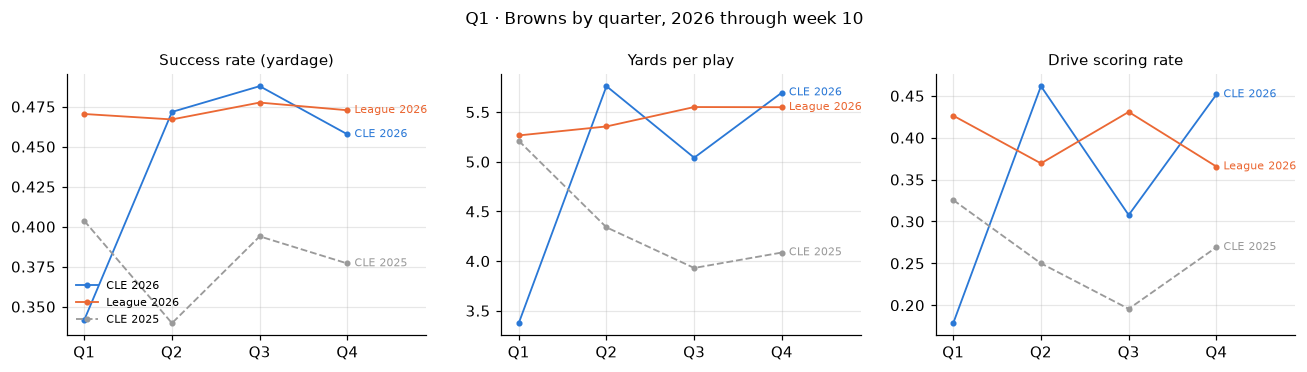

In [29]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, m, lab in zip(axs, ["succ_raw", "yds", "score"], ["Success rate (yardage)", "Yards per play", "Drive scoring rate"]):
    for k, c, ls in [("CLE 2026", BLUE, "-"), ("League 2026", ORANGE, "-"), ("CLE 2025", GREY, "--")]:
        y = tabs[k][m]
        ax.plot(range(1, 5), y, color=c, ls=ls, marker="o", ms=3, label=k)
        ax.annotate(k, (4.08, y.iloc[-1]), color=c, fontsize=7, va="center")
    ax.set_xticks(range(1, 5), ["Q1", "Q2", "Q3", "Q4"]); ax.set_title(lab, fontsize=10); ax.set_xlim(.8, 4.9)
axs[0].legend(fontsize=7, frameon=False, loc="lower left")
fig.suptitle(f"Q1 · Browns by quarter, 2026 through week {CUTOFF_WEEK}", fontsize=11); fig.tight_layout(); plt.show()

### Reading (Q1)
**They start slow, and almost all of it is the 1st quarter.** CLE's Q1 is awful: success 34% vs 47% for the league, 3.4 yards/play vs 5.3, 18% of drives scoring vs 43%, and 1.3 points per game vs 4.4. From Q2 onward they sit at or a little above the league (Q4 success 46% vs 47%, Q4 drive scoring 45% vs 37%).

- **Q1-3 vs league:** behind on drive scoring (−0.096 [−0.170, −0.026]) and first-down rate (−0.050 [−0.100, −0.004]). Success (−0.034) spans 0.
- **Q4 vs league:** every gap is near 0 and every interval spans 0 (success −0.015 [−0.078, +0.052], drive scoring +0.086 [−0.067, +0.251]).
- **Change from Q1-3 to Q4:** clear on drive scoring (+0.182 [+0.023, +0.357]) and points per drive (+1.14 [+0.34, +2.05]). Not clear on the clock-neutral per-play stats (success +0.019 [−0.052, +0.093], first downs +0.043 [−0.003, +0.090]).

So "slow starters, average finishers" holds, with one sharpening: it's a **1st-quarter** problem, not a quarters 1-3 problem. The per-play offense doesn't get better late. What improves is the number of drives that end in points, and Q2-Q3 explain that. CLE 2025 was below the league in every quarter, so 2026 is a real step up from Q2 onward, not just a 4th-quarter thing.

## Q2 · Better than a normal team in the same spot? (§7.2)
CLE's 4th-quarter offense when trailing or tied, against league teams that were in the **same** spot (margin bin × time bin). "Raw" compares CLE with all league trailing/tied 4th-quarter offense; "matched" re-weights the league to CLE's situations. The difference between the two shows how much of the raw number is just game state (e.g. being 17 down against soft coverage).

**What to look for:** the matched column for `succ_raw`, `fd` and drive `score`. Near 0 means they did what any team does in those spots. Also check `n`: CLE has only a few dozen such plays.

In [30]:
def cells(df, sign):
    "sign=-1: trailing/tied (margin bins tied,1-3,4-8,9-16,17+); sign=+1: leading (1-3,...,17+)"
    a = (sign * df.sd).to_numpy()
    mb = np.digitize(a, [1, 4, 9, 17])
    tb = np.digitize(df.gsr.to_numpy(), [120, 300, 600])
    return mb * 4 + tb
C = 20
P4, D4 = P[(P.season == CUR) & P.qtr.eq(4) & P.sd.notna()].copy(), D[(D.season == CUR) & D.qtr.eq(4) & D.sd.notna()].copy()
P4["cT"], D4["cT"] = cells(P4, -1), cells(D4, -1)
P4["cL"], D4["cL"] = cells(P4, +1), cells(D4, +1)

bt, lt = P4[(P4.posteam == TEAM) & (P4.sd <= 0)], P4[(P4.posteam != TEAM) & (P4.sd <= 0)]
bdt, ldt = D4[(D4.posteam == TEAM) & (D4.sd <= 0)], D4[(D4.posteam != TEAM) & (D4.sd <= 0)]
out = []
for m in PLAYM + DRIVEM:
    xb, xl = (bt, lt) if m in PLAYM else (bdt, ldt)
    er, dr_ = matched(xb, popB, xl, popL, m)
    em, dm = matched(xb, popB, xl, popL, m, "cT", C)
    out.append(dict(metric=m, n=len(xb), CLE=xb[m].mean(), raw=fmt(er, dr_), matched=fmt(em, dm)))
    if m in ("succ_raw", "fd", "score", "pts", "epa"): log("Q2", f"CLE trailing/tied Q4 matched gap {m}", em, dm)
    if m == "pts": q2_pts = (em, dm, len(xb))
print(pd.DataFrame(out).set_index("metric").to_string())
print("\nCLE trailing/tied Q4 plays by situation:")
print(pd.crosstab(pd.cut(-bt.sd, [-1, 0, 3, 8, 16, 99], labels=["tied", "1-3", "4-8", "9-16", "17+"]),
                  pd.cut(bt.gsr, [-1, 120, 300, 600, 900], labels=["2:00-0", "5:00-2:00", "10:00-5:00", "15:00-10:00"])).to_string())

            n    CLE                      raw                  matched
metric                                                                
succ_raw  164  0.494  +0.012 [-0.058, +0.087]  +0.019 [-0.056, +0.105]
fd        164  0.323  +0.009 [-0.048, +0.076]  +0.026 [-0.036, +0.098]
yds       164  6.299  +0.496 [-0.652, +2.023]  +0.703 [-0.524, +2.474]
epa       164  0.116  +0.093 [-0.032, +0.236]  +0.124 [-0.007, +0.282]
score      25  0.520  +0.120 [-0.074, +0.348]  +0.123 [-0.044, +0.343]
pts        25  2.840  +0.542 [-0.379, +1.654]  +0.718 [-0.246, +2.013]

CLE trailing/tied Q4 plays by situation:
gsr   2:00-0  5:00-2:00  10:00-5:00  15:00-10:00
sd                                              
tied      18          4          11           12
1-3        5          4          12            3
4-8        9         13          18           13
17+        6         10           9           17


### Reading (Q2)
**A bit better than a typical team chasing the game, but not distinguishable from noise.** This covers 164 plays and 25 drives. Every matched gap points positive and every interval spans 0:
- success +0.019 [−0.056, +0.105]
- first-down rate +0.026 [−0.036, +0.098]
- drive scoring +0.123 [−0.044, +0.343] (52% of these drives scored)
- points per drive +0.72 [−0.25, +2.01]

EPA is the strongest (+0.124 [−0.007, +0.282]), but EPA is the measure we said not to lead with late in games. Raw and matched barely differ, so game state isn't inflating the numbers. CLE had no plays down 9-16, and most of its plays came tied or one score down. **In the spots where comebacks happen, CLE's offense was average to good, not exceptional.**

## Q3 · How much is the opponent? (§7.3)
Opponents' 4th-quarter offense while **leading CLE**, vs league leaders in the same cells. Phase 3 found leaders get conservative and lose value late. The question is whether CLE's opponents did that *more* than usual. The last table turns Q2 and Q3 into points: CLE's points above a typical team in its spots, vs points its opponents left on the table relative to typical leaders.

**What to look for:** `is_run` and `secs` (did they sit on the ball more than typical leaders?), then `score`/`pts` per drive. A negative matched gap on opponent `pts` that's as big as CLE's positive gap means half the story is the other team.

In [31]:
ot, lo_ = P4[(P4.defteam == TEAM) & (P4.sd > 0)], P4[(P4.defteam != TEAM) & (P4.posteam != TEAM) & (P4.sd > 0)]
odt, ldo = D4[(D4.defteam == TEAM) & (D4.sd > 0)], D4[(D4.defteam != TEAM) & (D4.posteam != TEAM) & (D4.sd > 0)]
out = []
for m in ["is_run", "secs"] + PLAYM + ["score", "three_out", "pts", "dur"]:
    xb, xl = (odt, ldo) if m in ("score", "three_out", "pts", "dur") else (ot, lo_)
    em, dm = matched(xb, popB, xl, popL, m, "cL", C)
    out.append(dict(metric=m, n=int(xb[m].notna().sum()), opp=xb[m].mean(), matched=fmt(em, dm)))
    if m in ("is_run", "succ_raw", "score", "pts"): log("Q3", f"opp leading CLE Q4 matched gap {m}", em, dm)
    if m == "pts": q3_pts = (em, dm, len(xb))
print(pd.DataFrame(out).set_index("metric").to_string())

(e2, d2, n2), (e3, d3, n3) = q2_pts, q3_pts
att = pd.DataFrame({"drives": [n2, n3], "pts per drive vs typical": [fmt(e2, d2), fmt(e3, d3)],
                    "total pts vs typical": [fmt(e2 * n2, d2 * n2, 1), fmt(e3 * n3, d3 * n3, 1)]},
                   index=["CLE offense, trailing/tied Q4", "Opponents, leading CLE in Q4"])
print("\n" + att.to_string())
log("Q3", "CLE excess Q4 pts (trailing/tied) vs typical", e2 * n2, d2 * n2)
log("Q3", "opp Q4 pts vs typical leaders", e3 * n3, d3 * n3)

            n     opp                      matched
metric                                            
is_run     31   0.677      +0.015 [-0.082, +0.151]
secs       20  32.450      -2.055 [-8.375, +6.131]
succ_raw   31   0.226      -0.238 [-0.407, -0.109]
fd         31   0.032      -0.235 [-0.303, -0.171]
yds        31   1.903      -3.243 [-4.541, -1.099]
epa        31  -0.521      -0.526 [-0.979, -0.341]
score       9   0.000      -0.275 [-0.377, -0.171]
three_out   9   0.778      +0.467 [+0.140, +0.709]
pts         9   0.000      -1.370 [-1.945, -0.839]
dur         9  84.444  -78.205 [-136.335, -28.521]

                               drives pts per drive vs typical total pts vs typical
CLE offense, trailing/tied Q4      25  +0.718 [-0.246, +2.013]  +17.9 [-6.1, +50.3]
Opponents, leading CLE in Q4        9  -1.370 [-1.945, -0.839]  -12.3 [-17.5, -7.6]


/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/3346784327.py:31: RuntimeWarning: invalid value encountered in divide
  return np.where(ok, st - nt * lb, 0).sum(-1) / np.where(ok, nt, 0).sum(-1)
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/3346784327.py:31: RuntimeWarning: invalid value encountered in divide
  return np.where(ok, st - nt * lb, 0).sum(-1) / np.where(ok, nt, 0).sum(-1)
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/3346784327.py:31: RuntimeWarning: invalid value encountered in divide
  return np.where(ok, st - nt * lb, 0).sum(-1) / np.where(ok, nt, 0).sum(-1)
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/3346784327.py:31: RuntimeWarning: invalid value encountered in divide
  return np.where(ok, st - nt * lb, 0).sum(-1) / np.where(ok, nt, 0).sum(-1)
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/3346784327.py:31: RuntimeWarning: invalid value encountered in divide
  return np.where(ok, 

### Reading (Q3)
**The clearest effect in the case study: opponents' offense collapsed while leading CLE in the 4th.** They had 9 drives and 31 plays and got 0 points, 1 first down (3%), 78% three-and-outs and 23% success. Against league leaders in the same spots:
- success −0.238 [−0.407, −0.109]
- drive scoring −0.275 [−0.377, −0.171]
- points per drive −1.37 [−1.95, −0.84]

But they **didn't sit on the ball more than typical leaders**: run rate +0.015 [−0.082, +0.151], clock per play −2 s [−8, +6]. So this isn't the Phase 3 mechanism (leaders choosing to go conservative). They called the usual plays and got stopped. The design can't separate bad opponent execution from good Browns defense. With normal-looking play calling, though, the more natural reading is **the Browns' defense closing games out**.

In points: CLE's offense was about **+18** above typical trailing teams [−6, +50]. Opponents were about **−12** below typical leaders [−18, −8]. The defensive side is the smaller number, but it's the only one with an interval clear of 0. Caveat: 9 drives across 10 games.

## Q4 · Will it last? Regression to the mean, 2016-2025 (§7.4)
Each team-season is split into games 1-10 and 11+. Flagged = 4 or more GWD wins in the first 10 (plus a top-5% sensitivity). For those teams: what happened next? Then, across every team-season: which early-season numbers actually predict the rest of the season?

**What to look for:** in the flagged rows, whether `rest` falls back toward the league line. In the prediction table, whether early one-score win % predicts much (classic finding: barely), compared with point differential.

In [32]:
GH = GR[GR.season < CUR]
def agg(g):
    a = g.groupby(["season", "team"]).agg(G=("win", "size"), wp=("wpts", "mean"), gwd=("gwd", "mean"), cb=("cb", "mean"),
                                         osG=("one_score", "sum"), osW=("os_win", "sum"), pdg=("margin", "mean"),
                                         pf=("pf", "sum"), pa=("pa", "sum"))
    a["os_wp"] = a.osW / a.osG.where(a.osG > 0)
    return a
E, Rst, Full = agg(GH[GH.game_no <= EARLY_N]), agg(GH[GH.game_no > EARLY_N]), agg(GH)
TS = E.join(Rst, lsuffix="_e", rsuffix="_r")
nxt = Full.wp.rename("wp_next"); nxt.index = nxt.index.set_levels(nxt.index.levels[0] - 1, level="season")
TS = TS.join(nxt)
TS["gwd_n_e"] = (TS.gwd_e * TS.G_e).round()
top5 = TS.gwd_n_e.quantile(.95)
TS["flag"], TS["flag5"] = TS.gwd_n_e >= GWD_MIN, TS.gwd_n_e >= top5

print("GWD wins in the first", EARLY_N, "games, 2016-2025 team-seasons:")
print(TS.gwd_n_e.value_counts().sort_index().to_frame("team-seasons").T.to_string())
cle_e = agg(GR[(GR.season == CUR) & (GR.team == TEAM) & (GR.game_no <= EARLY_N)]).iloc[0]
print(f"CLE 2026: {int(round(cle_e.gwd * cle_e.G))} GWD wins in {int(cle_e.G)} games -> share of history with at least that many:",
      f"{(TS.gwd_n_e >= round(cle_e.gwd * cle_e.G)).mean():.1%} | top-5% threshold = {top5:.0f}")

GWD wins in the first 10 games, 2016-2025 team-seasons:
gwd_n_e       0.0  1.0  2.0  3.0  4.0  5.0  6.0
team-seasons   62   93   88   52   14   10    1
CLE 2026: 6 GWD wins in 10 games -> share of history with at least that many: 0.3% | top-5% threshold = 4


/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/1527612450.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  TS = E.join(Rst, lsuffix="_e", rsuffix="_r")


In [33]:
def bmean(x, B=None):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    idx = rng.integers(0, len(x), (B or NBOOT, len(x)))
    return x.mean(), x[idx].mean(1)

cols = [("wp", "win %"), ("gwd", "GWD wins / game"), ("cb", "comeback wins / game"), ("os_wp", "one-score win %"), ("pdg", "point diff / game")]
out = []
for fl, lab in [("flag", f">= {GWD_MIN} GWD"), ("flag5", f"top 5% (>= {top5:.0f})")]:
    T = TS[TS[fl]]
    for c, nm in cols:
        ch, chd = bmean(T[f"{c}_r"] - T[f"{c}_e"])
        out.append(dict(group=lab, n=len(T), metric=nm, early=T[f"{c}_e"].mean(), rest=T[f"{c}_r"].mean(),
                        league_rest=TS[f"{c}_r"].mean(), change=fmt(ch, chd)))
        if fl == "flag" and c in ("wp", "gwd", "os_wp"): log("Q4", f"flagged teams rest - early {nm}", ch, chd)
    out.append(dict(group=lab, n=len(T), metric="next-season win %", early=T.wp_e.mean(), rest=T.wp_next.mean(),
                    league_rest=TS.wp_next.mean(), change=fmt(*bmean(T.wp_next - T.wp_e))))
Q4T = pd.DataFrame(out).set_index(["group", "metric"])
print(Q4T.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nFlagged team-seasons:", ", ".join(f"{t} {s} ({int(n)})" for (s, t), n in TS[TS.flag].gwd_n_e.items()))

                                     n  early   rest  league_rest                   change
group         metric                                                                      
>= 4 GWD      win %                 25  0.656  0.511        0.500  -0.145 [-0.212, -0.082]
              GWD wins / game       25  0.448  0.173        0.157  -0.275 [-0.347, -0.197]
              comeback wins / game  25  0.380  0.143        0.115  -0.237 [-0.312, -0.166]
              one-score win %       25  0.743  0.525        0.492  -0.219 [-0.334, -0.103]
              point diff / game     25  0.568 -0.559        0.026  -1.127 [-3.042, +0.683]
              next-season win %     25  0.656  0.497        0.500  -0.153 [-0.249, -0.061]
top 5% (>= 4) win %                 25  0.656  0.511        0.500  -0.145 [-0.208, -0.084]
              GWD wins / game       25  0.448  0.173        0.157  -0.275 [-0.341, -0.197]
              comeback wins / game  25  0.380  0.143        0.115  -0.237 [-0.306, -0.159]

In [34]:
def corr_ci(x, y, B=None):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = ~(np.isnan(x) | np.isnan(y)); x, y = x[ok], y[ok]
    idx = rng.integers(0, len(x), (B or NBOOT, len(x))); xs, ys = x[idx], y[idx]
    xs = xs - xs.mean(1, keepdims=True); ys = ys - ys.mean(1, keepdims=True)
    return np.corrcoef(x, y)[0, 1], (xs * ys).sum(1) / np.sqrt((xs ** 2).sum(1) * (ys ** 2).sum(1)), len(x)

os_ok = TS[(TS.osG_e >= 3) & (TS.osG_r >= 2)]
preds = [("early one-score win %", "rest one-score win %", os_ok.os_wp_e, os_ok.os_wp_r),
         ("early win %", "rest win %", TS.wp_e, TS.wp_r),
         ("early point diff / game", "rest win %", TS.pdg_e, TS.wp_r),
         ("early one-score win %", "rest win %", os_ok.os_wp_e, os_ok.wp_r),
         ("early GWD wins / game", "rest win %", TS.gwd_e, TS.wp_r)]
out = []
for a, bb, x, y in preds:
    rr, rd, n = corr_ci(x, y)
    out.append(dict(predictor=a, outcome=bb, n=n, r=fmt(rr, rd)))
    log("Q4", f"corr({a}, {bb})", rr, rd)
print(pd.DataFrame(out).to_string(index=False))

# forecast: rest-of-season win % from early point diff + early one-score win %
F = os_ok[["pdg_e", "os_wp_e", "wp_r"]].dropna()
X = np.column_stack([np.ones(len(F)), F.pdg_e, F.os_wp_e]); beta = np.linalg.lstsq(X, F.wp_r, rcond=None)[0]
pyth = cle_e.pf ** 2.37 / (cle_e.pf ** 2.37 + cle_e.pa ** 2.37)
fc = beta @ [1, cle_e.pdg, cle_e.os_wp if not np.isnan(cle_e.os_wp) else .5]
print(f"\nrest win % = {beta[0]:.3f} + {beta[1]:.4f} x pt diff/game + {beta[2]:.3f} x one-score win %")
print(f"CLE 2026 early: win % {cle_e.wp:.3f} | pt diff/game {cle_e.pdg:+.1f} | one-score {int(cle_e.osW)}/{int(cle_e.osG)} "
      f"| Pythagorean win % {pyth:.3f} | forecast rest win % {fc:.3f}")
log("Q4", "CLE 2026 forecast rest-of-season win %", fc)
log("Q4", "CLE 2026 Pythagorean win % (early)", pyth)

              predictor              outcome   n                       r
  early one-score win % rest one-score win % 289 +0.184 [+0.078, +0.292]
            early win %           rest win % 320 +0.433 [+0.348, +0.525]
early point diff / game           rest win % 320 +0.453 [+0.368, +0.529]
  early one-score win %           rest win % 289 +0.222 [+0.119, +0.318]
  early GWD wins / game           rest win % 320 +0.121 [+0.020, +0.223]

rest win % = 0.471 + 0.0171 x pt diff/game + 0.061 x one-score win %
CLE 2026 early: win % 0.600 | pt diff/game -3.2 | one-score 6/8 | Pythagorean win % 0.408 | forecast rest win % 0.462


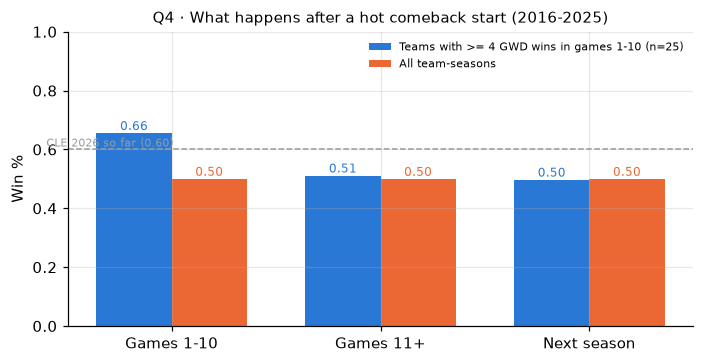

In [35]:
T = TS[TS.flag]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(3); w = .36
v1 = [T.wp_e.mean(), T.wp_r.mean(), T.wp_next.mean()]
v2 = [TS.wp_e.mean(), TS.wp_r.mean(), TS.wp_next.mean()]
for xs, v, c, lab in [(x - w / 2, v1, BLUE, f"Teams with >= {GWD_MIN} GWD wins in games 1-{EARLY_N} (n={len(T)})"), (x + w / 2, v2, ORANGE, "All team-seasons")]:
    ax.bar(xs, v, w, color=c, label=lab)
    for xi, vi in zip(xs, v): ax.text(xi, vi + .01, f"{vi:.2f}", ha="center", fontsize=8, color=c)
ax.axhline(cle_e.wp, color=GREY, ls="--", lw=1); ax.text(-.6, cle_e.wp + .01, f"CLE 2026 so far ({cle_e.wp:.2f})", fontsize=7, color=GREY, ha="left")
ax.set_xticks(x, [f"Games 1-{EARLY_N}", f"Games {EARLY_N + 1}+", "Next season"]); ax.set_ylabel("Win %"); ax.set_ylim(0, 1)
ax.legend(fontsize=7, frameon=False, loc="upper right"); ax.set_title("Q4 · What happens after a hot comeback start (2016-2025)", fontsize=10)
fig.tight_layout(); plt.show()

### Reading (Q4)
**Hot comeback starts regress almost all the way back.** Since 2016, 25 team-seasons had 4+ GWD wins in their first 10 games. The top-5% cut is also 4, so the sensitivity rows just repeat the primary ones. Only one team-season had 6 like CLE (DET 2016), which is 0.3% of team-seasons.

For the flagged teams, from early season to the rest of the season (league average in brackets):
- win %: 0.656 → **0.511** (−0.145 [−0.212, −0.082]; league 0.500)
- GWD wins per game: 0.448 → **0.173** (league 0.157)
- one-score win %: 0.743 → **0.525** (league 0.492)
- next-season win %: **0.497**
- point differential: about +0.6 per game early, −0.6 per game after. These were roughly average teams winning close games.

**What predicts the rest of the season:**
- early point differential: r +0.45
- early win %: r +0.43
- early one-score win %, predicting rest one-score win %: only r +0.18 [+0.08, +0.29]
- early GWD rate: r +0.12

**CLE 2026:** 6-4 with a point differential of −3.2 per game, 6-2 in one-score games, and a Pythagorean win % of 0.408 (about 4 wins out of 10). The model forecasts 0.462 for the remaining 7 games, about 3 wins, so a finish near 9-8. Expect the close-game record to drift toward a coin flip.

## Q5 · Clutch gene: does late-game over-performance persist? (§7.5)
Residual = clutch mean − own non-clutch mean − the league's clutch-minus-normal gap that season (so 0 = as good in the clutch as usual, relative to everyone). Persistence is checked two ways, against two references:
- **noise band**: the range of r you'd get if "clutch" plays were a random draw from the unit's plays (should centre on 0);
- **detectability reference**: how strongly a unit's plain *level* on clutch-sized random samples persists. If even real skill barely shows on samples this small, a null clutch result is weak evidence.

New pandas move: `groupby(...).rank()` on random numbers draws a random subset of the same size within each unit-season (the reshuffle).

**What to look for:** whether `r` sits above the noise band (QB and team, succ_raw first). Then Watson 2026's residual and its shrunk forecast (r × residual).

In [36]:
def clutch_flag(d, margin_rule="trail"):
    lo = -CLUTCH_MARGIN; hi = 0 if margin_rule == "trail" else CLUTCH_MARGIN
    return d.qtr.eq(4) & (d.gsr <= CLUTCH_GSR) & d.sd.between(lo, hi)

def resid(d, keys, m, flag):
    g = d.groupby(keys + [flag])[m].agg(["mean", "size"]).unstack(flag)
    o = pd.DataFrame({"c": g[("mean", True)], "n_c": g[("size", True)], "o": g[("mean", False)], "n_o": g[("size", False)]})
    lg = d.groupby(["season", flag])[m].mean().unstack(flag)
    o["res"] = o.c - o.o - (lg[True] - lg[False]).reindex(o.index.get_level_values("season")).to_numpy()
    return o

def pairs(o, mode):
    if mode == "split":
        a, b = o.xs(0, level="par"), o.xs(1, level="par"); mc, mo = MIN_HALF, MIN_O_HALF
    else:
        a = o; b = o.copy(); b.index = b.index.set_levels(b.index.levels[1] - 1, level="season"); mc, mo = MIN_SEASON, MIN_O_SEASON
    j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
    return j[(j.n_c_a >= mc) & (j.n_c_b >= mc) & (j.n_o_a >= mo) & (j.n_o_b >= mo)]

def persistence(d, unit, m, mode, flag="clutch"):
    keys = [unit, "season"] + (["par"] if mode == "split" else [])
    d = d[d[m].notna()]
    j = pairs(resid(d, keys, m, flag), mode)
    r_obs, r_d, n = corr_ci(j.res_a, j.res_b)
    # reshuffles: same number of 'clutch' plays per group, drawn at random
    k = d.groupby(keys)[flag].transform("sum").to_numpy()
    null, ref = [], []
    for _ in range(NSHUF):
        rk = pd.Series(rng.random(len(d)), index=d.index).groupby([d[c] for c in keys]).rank(method="first").to_numpy()
        jj = pairs(resid(d.assign(_f=rk <= k), keys, m, "_f"), mode)
        null.append(np.corrcoef(jj.res_a, jj.res_b)[0, 1]); ref.append(np.corrcoef(jj.c_a, jj.c_b)[0, 1])
    return dict(r=r_obs, r_draws=r_d, n=n, null_lo=np.percentile(null, 2.5), null_hi=np.percentile(null, 97.5),
                ref=np.mean(ref), pairs=j)

P["clutch"] = clutch_flag(P); P["clutch_wide"] = clutch_flag(P, "wide")
DB = P[P.qb_id.notna()]
Hq, Ht = DB[DB.season < CUR], P[P.season < CUR]
print("clutch dropbacks per QB-season (QB-seasons with 200+ dropbacks):")
print(Hq.groupby(["qb_id", "season"]).clutch.agg(["sum", "size"]).query("size >= 200")["sum"].describe()[["count", "25%", "50%", "75%"]].to_string())

clutch dropbacks per QB-season (QB-seasons with 200+ dropbacks):
count    363.0
25%       15.0
50%       24.0
75%       33.0


In [37]:
runs = [("QB", Hq, "qb_id", m, mode, "clutch") for m in ["succ_raw", "fd", "yds", "epa"] for mode in ["split", "season"]]
runs += [("Team", Ht, "posteam", m, mode, "clutch") for m in ["succ_raw", "fd"] for mode in ["split", "season"]]
runs += [("QB, wide window", Hq, "qb_id", "succ_raw", mode, "clutch_wide") for mode in ["split", "season"]]
out, PERS = [], {}
for unit, d, u, m, mode, fl in runs:
    res = persistence(d, u, m, mode, fl); PERS[(unit, m, mode)] = res
    out.append(dict(unit=unit, metric=m, test="odd vs even games" if mode == "split" else "season t vs t+1", pairs=res["n"],
                    r=fmt(res["r"], res["r_draws"]), noise_band=f"[{res['null_lo']:+.3f}, {res['null_hi']:+.3f}]",
                    detectability_ref=f"{res['ref']:+.3f}"))
    if m in ("succ_raw", "fd") and fl == "clutch": log("Q5", f"{unit} clutch persistence {m} ({mode})", res["r"], res["r_draws"],
                                                       f"noise [{res['null_lo']:+.3f},{res['null_hi']:+.3f}] ref {res['ref']:+.3f}")
Q5T = pd.DataFrame(out)
print(Q5T.to_string(index=False))

/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warni

           unit   metric              test  pairs                       r       noise_band detectability_ref
             QB succ_raw odd vs even games     87 +0.166 [-0.077, +0.386] [-0.210, +0.216]            +0.090
             QB succ_raw   season t vs t+1     62 +0.003 [-0.243, +0.225] [-0.261, +0.235]            +0.088
             QB       fd odd vs even games     87 +0.069 [-0.142, +0.278] [-0.248, +0.170]            +0.057
             QB       fd   season t vs t+1     62 +0.083 [-0.148, +0.310] [-0.264, +0.214]            +0.066
             QB      yds odd vs even games     87 -0.058 [-0.273, +0.159] [-0.192, +0.199]            +0.059
             QB      yds   season t vs t+1     62 +0.049 [-0.162, +0.258] [-0.287, +0.221]            +0.054
             QB      epa odd vs even games     87 +0.082 [-0.123, +0.266] [-0.235, +0.186]            +0.032
             QB      epa   season t vs t+1     62 +0.195 [-0.043, +0.398] [-0.274, +0.217]            +0.027
           Team suc

/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
/var/folders/k6/03408s651m5grfvn5_9rpgz00000gn/T/ipykernel_5354/4058206472.py:17: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")


In [38]:
# Watson / CLE 2026 on the historical distribution (succ_raw primary, fd secondary)
r_qb = max(PERS[("QB", "succ_raw", "season")]["r"], 0); r_tm = max(PERS[("Team", "succ_raw", "season")]["r"], 0)
out = []
for unit, d, u, ids, rr in [("QB", DB, "qb_id", None, r_qb), ("Team", P, "posteam", [TEAM], r_tm)]:
    for m in ["succ_raw", "fd"]:
        o = resid(d[d[m].notna()], [u, "season"], m, "clutch")
        hist = o.query(f"season < {CUR} and n_c >= {MIN_SEASON} and n_o >= {MIN_O_SEASON}").res
        now = o.xs(CUR, level="season")
        if unit == "QB":
            top = DB[(DB.season == CUR) & (DB.posteam == TEAM)].groupby(["qb_id", "qb_name"]).size()
            top = top[top >= 50].sort_values(ascending=False)
            sel = [(i, nm) for i, nm in top.index]
        else:
            sel = [(TEAM, TEAM)]
        for i, nm in sel:
            if i not in now.index: continue
            x = now.loc[i]
            pctl = (hist < x.res).mean()
            out.append(dict(unit=unit, who=nm, metric=m, clutch_plays=int(x.n_c), clutch=x.c, normal=x.o,
                            residual=x.res, pctl_vs_history=f"{pctl:.0%}", forecast_next=rr * x.res if m == "succ_raw" else np.nan))
            if m == "succ_raw": log("Q5", f"{nm} 2026 clutch residual succ_raw", x.res, note=f"pctl {pctl:.0%}, n_c {int(x.n_c)}")
Q5W = pd.DataFrame(out)
print(Q5W.to_string(index=False))
print(f"\nforecast_next = r(season t vs t+1, floored at 0) x residual; r used: QB {r_qb:.3f}, team {r_tm:.3f}")

unit      who   metric  clutch_plays  clutch  normal  residual pctl_vs_history  forecast_next
  QB D.Watson succ_raw            40   0.475   0.446     0.024             55%      7.764e-05
  QB D.Watson       fd            40   0.300   0.298    -0.013             40%            NaN
Team      CLE succ_raw            53   0.453   0.444     0.005             51%      0.000e+00
Team      CLE       fd            53   0.302   0.249     0.017             59%            NaN

forecast_next = r(season t vs t+1, floored at 0) x residual; r used: QB 0.003, team 0.000


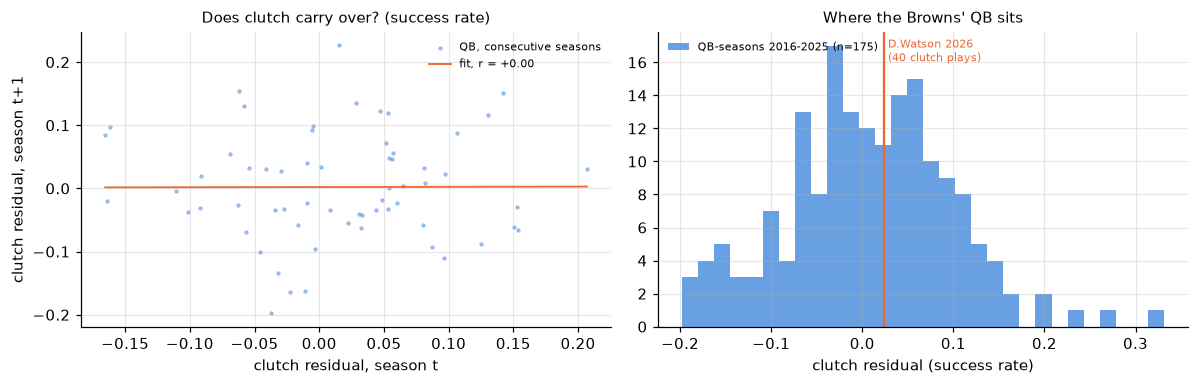

In [39]:
oq = resid(DB[DB.succ_raw.notna()], ["qb_id", "season"], "succ_raw", "clutch")
hist = oq.query(f"season < {CUR} and n_c >= {MIN_SEASON} and n_o >= {MIN_O_SEASON}").res
j = PERS[("QB", "succ_raw", "season")]["pairs"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].scatter(j.res_a, j.res_b, s=8, color=BLUE, alpha=.5, lw=0, label="QB, consecutive seasons")
k = np.polyfit(j.res_a, j.res_b, 1); xx = np.linspace(j.res_a.min(), j.res_a.max(), 2)
axs[0].plot(xx, np.polyval(k, xx), color=ORANGE, label=f"fit, r = {PERS[('QB', 'succ_raw', 'season')]['r']:+.2f}")
axs[0].set_xlabel("clutch residual, season t"); axs[0].set_ylabel("clutch residual, season t+1")
axs[0].set_title("Does clutch carry over? (success rate)", fontsize=10); axs[0].legend(fontsize=7, frameon=False)
axs[1].hist(hist, bins=30, color=BLUE, alpha=.7, label=f"QB-seasons 2016-2025 (n={len(hist)})")
for _, rw in Q5W[(Q5W.unit == "QB") & (Q5W.metric == "succ_raw")].head(1).iterrows():
    axs[1].axvline(rw.residual, color=ORANGE, lw=1.5)
    axs[1].text(rw.residual, axs[1].get_ylim()[1] * .9, f" {rw.who} 2026\n ({rw.clutch_plays} clutch plays)", color=ORANGE, fontsize=7)
axs[1].set_xlabel("clutch residual (success rate)"); axs[1].set_title("Where the Browns' QB sits", fontsize=10)
axs[1].legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

### Reading (Q5)
**No evidence of a clutch gene. But this data couldn't show one unless it were huge.**
- **QB, primary window:** split-half r +0.166 [−0.077, +0.386] and season-to-season r +0.003. Both are inside their noise bands (about ±0.21-0.25).
- **Team:** −0.001 and −0.022.
- **All 12 primary tests** (QB and team, every metric) sit inside their noise bands.

The **detectability reference** is the key number. A QB's plain success rate, measured on clutch-sized samples (a median of 24 dropbacks a season), persists at only r ≈ +0.09. Real, stable skill barely shows through samples that small. Even if clutch skill varied as much as ordinary QB skill does, we'd expect r ≈ 0.1, which is inside the band. So the honest conclusion is **"clutch isn't detectable"**, not "clutch is proven fake". The practical point is the same either way: for forecasting, one season's clutch record is almost all noise.

**One flag.** The wide window (one-score leads added) gives a season-to-season r of +0.201 [+0.037, +0.347], above its noise band [−0.184, +0.175]. But it's 1 of 14 tests and a sensitivity check, and the split-half version doesn't back it (+0.055). If it's real, the likely source is a stable way of managing a lead (the Phase 3 leader effect), not clutch. It isn't a finding to lean on without a pre-specified follow-up.

**Watson 2026:** 40 clutch dropbacks, a lot because the Browns have trailed late so often. His success rate is 47.5% in clutch spots vs 44.6% the rest of the time. Residual +0.024, the **55th percentile** of QB-seasons, with a next-season forecast of about 0. **The Browns as a team:** +0.005, the **51st percentile**. In clutch spots they play like themselves.

## Scoreboard and summary

In [40]:
SBD = pd.DataFrame(SB)
SBD.to_csv(RES / "browns_scoreboard.csv", index=False)
print(SBD.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

 q                                              what     est      lo      hi                             note
Q1                          CLE-league Q1-3 succ_raw  -0.034  -0.104  +0.032                                 
Q1                            CLE-league Q4 succ_raw  -0.015  -0.078  +0.052                                 
Q1                               CLE-league Q1-3 epa  -0.106  -0.214  -0.007                                 
Q1                                 CLE-league Q4 epa  +0.010  -0.101  +0.134                                 
Q1                             CLE-league Q1-3 score  -0.096  -0.170  -0.026                                 
Q1                               CLE-league Q4 score  +0.086  -0.067  +0.251                                 
Q2         CLE trailing/tied Q4 matched gap succ_raw  +0.019  -0.056  +0.105                                 
Q2               CLE trailing/tied Q4 matched gap fd  +0.026  -0.036  +0.098                                 
Q2        

### Summary
**Q1.** The Browns start slow, specifically in the **1st quarter** (18% of drives score vs 43% for the league). From Q2 on they're about league average. Per-play stats don't improve in the 4th; what changes is that more drives end in points.

**Q2.** When trailing or tied in the 4th, their offense is a bit above a typical team in the same spots (drive scoring +0.12, points per drive +0.7), but every interval spans 0 with 25 drives.

**Q3.** The one clear effect: opponents leading CLE in the 4th scored **0 points on 9 drives** (78% three-and-outs), well below typical leaders. They weren't more conservative than usual, so it reads as the Browns' defense closing, not opponents giving games away.

**Q4.** History says comeback-heavy starts regress hard. Teams with 4+ GWD wins in 10 games played .511 football afterwards and .497 the next season. CLE's 6-4 comes with a −3.2 point differential per game (Pythagorean 0.408). Forecast for the remaining games: about .46, a finish near 9-8.

**Q5.** No detectable clutch persistence for QBs or teams. The samples are too small for even real skill to show (detectability reference r ≈ 0.09). Watson's 2026 clutch residual is at the 55th percentile, so he's playing like himself.

**One line:** *The Browns aren't clutch. They start badly, play like a normal offense once they're chasing, and their defense has shut out every opponent 4th-quarter drive while the Browns trailed. The rest is close-game luck, and history says it runs out.*

**Link to the project:** this is the same lesson as Phases 1-3. What looks like a late-game surge mostly comes from somewhere other than late-game skill. Here that's a bad start, the other side of the ball, and close-game luck, rather than a pricing effect or leaders' play calling.